In [25]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - 2
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + "/", f"({len(files)} files)")
        for f in files[:5]:
            print("  " * (depth + 1) + f)
            

input/ (0 files)
  datasets/ (0 files)
    hgunraj/ (0 files)


In [26]:
import os
base = "/kaggle/input/datasets/hgunraj"
for root, dirs, files in os.walk(base):
    depth = root[len(base):].count(os.sep)
    print("  " * depth + os.path.basename(root) + "/", f"({len(files)} files)", files[:3])
    if depth >= 3:
        dirs.clear()

hgunraj/ (0 files) []
  covidxct/ (4 files) ['metadata.csv', 'test_COVIDx_CT-3A.txt', 'train_COVIDx_CT-3A.txt']
    3A_images/ (425024 files) ['137covid_patient100_SR_2_IM00028.png', '137covid_patient100_SR_2_IM00029.png', '137covid_patient100_SR_2_IM00045.png']


In [27]:
import os
import pandas as pd

root = "/kaggle/input/datasets/hgunraj/covidxct"
print(os.listdir(root))

cols = ["filename", "label", "xmin", "ymin", "xmax", "ymax"]
train = pd.read_csv(f"{root}/train_COVIDx_CT-3A.txt", sep=" ", names=cols)
print(train.shape)
print(train.head(10))
print(train.label.value_counts())

meta = pd.read_csv(f"{root}/metadata.csv")
print(meta.head())

['3A_images', 'metadata.csv', 'test_COVIDx_CT-3A.txt', 'train_COVIDx_CT-3A.txt', 'val_COVIDx_CT-3A.txt']
(357518, 6)
               filename  label  xmin  ymin  xmax  ymax
0  NCP_96_1328_0032.png      2     9    94   512   405
1  NCP_96_1328_0035.png      2    10   106   512   405
2  NCP_96_1328_0036.png      2    10   105   512   406
3  NCP_96_1328_0037.png      2    11   104   512   406
4  NCP_96_1328_0038.png      2    11   103   512   406
5  NCP_96_1328_0039.png      2    12   102   512   406
6  NCP_96_1328_0040.png      2    12   102   512   406
7  NCP_96_1328_0041.png      2    12   101   512   406
8  NCP_96_1328_0042.png      2    12   100   512   406
9  NCP_96_1328_0043.png      2    13   100   512   406
label
2    294552
0     35996
1     26970
Name: count, dtype: int64
  patient id source country  sex  age    finding verified finding  \
0       CP_0   CNCB   China  NaN  NaN  Pneumonia              Yes   
1      CP_10   CNCB   China  NaN  NaN  Pneumonia              Yes   
2  

In [28]:
name = "NCP_96_1328_0032.png"
stem = name.replace(".png", "")
print(stem)
parts= stem.split("_")
print(parts)
print("_".join(parts[:2]))

def patient_id(filename):
    stem = filename.replace(".png", "")
    parts = stem.split("_")
    return "_".join(parts[:2])

print(patient_id("NCP_96_1328_0032.png"))
print(patient_id("CP_10_2001_0005.png"))

NCP_96_1328_0032
['NCP', '96', '1328', '0032']
NCP_96
NCP_96
CP_10


In [29]:
   train["patient_id"] = train["filename"].apply(patient_id)
   known = set(meta["patient id"])
   match = train["patient_id"].isin(known).mean()
   print(f"{match:.1%} of training slices matched a patient in metadata.csv")
   print(train[~train["patient_id"].isin(known)]["filename"].head(10))

20.6% of training slices matched a patient in metadata.csv
61756    coronacases_001-0085.png
61757    coronacases_001-0086.png
61758    coronacases_001-0087.png
61759    coronacases_001-0088.png
61760    coronacases_001-0089.png
61761    coronacases_001-0090.png
61762    coronacases_001-0091.png
61763    coronacases_001-0092.png
61764    coronacases_001-0093.png
61765    coronacases_001-0094.png
Name: filename, dtype: object


In [30]:
# 1. How does metadata write patient IDs for each source?
print(meta["source"].value_counts(), "\n")
for src, g in meta.groupby("source"):
    print(f"{src:25s}", list(g["patient id"].head(3)))

# 2. What naming patterns do the unmatched files use?
unmatched = train[~train["patient_id"].isin(known)]
prefix = unmatched["filename"].str.extract(r"^([A-Za-z]+)")[0]
print("\n", prefix.value_counts())
for p in prefix.value_counts().index:
    print(f"{p:20s}", unmatched.loc[prefix == p, "filename"].iloc[0])

source
CNCB               1854
STOIC              1176
MosMedData          756
iCTCF               709
TCIA                643
COVID-CTset         377
COVID-CT-MD         301
radiopaedia.org     105
Stony Brook          90
LIDC-IDRI            39
COVID-19-CT-Seg      18
Name: count, dtype: int64 

CNCB                      ['CP_0', 'CP_10', 'CP_1068']
COVID-19-CT-Seg           ['coronacases_001', 'coronacases_002', 'coronacases_003']
COVID-CT-MD               ['COVIDCTMD-P001', 'COVIDCTMD-P002', 'COVIDCTMD-P003']
COVID-CTset               ['patient1', 'patient10', 'patient100']
LIDC-IDRI                 ['LIDC-IDRI-0068', 'LIDC-IDRI-0071', 'LIDC-IDRI-0100']
MosMedData                ['study_0255', 'study_0256', 'study_0257']
STOIC                     ['STOIC-10011', 'STOIC-1002', 'STOIC-10032']
Stony Brook               ['A002304', 'A056642', 'A073761']
TCIA                      ['volume-covid19-A-0003', 'volume-covid19-A-0011', 'volume-covid19-A-0013']
iCTCF                     ['HUST

In [31]:
import re

def patient_id(filename):
    stem = filename.replace(".png", "")
    if stem.startswith(("NCP_", "CP_", "Normal_")):      # CNCB
        return "_".join(stem.split("_")[:2])
    if "_patient" in stem:                               # COVID-CTset
        return re.search(r"patient\d+", stem).group()
    if stem.startswith("volume-"):                       # TCIA
        return re.match(r"volume-covid19-A-\d+(_\d)?", stem).group()
    if stem.startswith("LIDC-IDRI-"):                    # LIDC-IDRI
        return "-".join(stem.split("-")[:3])
    if stem.startswith("radiopaedia-"):                  # radiopaedia, dash style
        return "-".join(stem.split("-")[:2])
    if stem.startswith("radiopaedia_"):                  # radiopaedia, underscore style
        return "radiopaedia_" + stem.split("_")[1]
    if re.match(r"A\d{6}-", stem):                       # Stony Brook
        return stem.split("-")[0]
    return stem.rsplit("-", 1)[0]   # STOIC, iCTCF, COVID-CT-MD, coronacases

In [32]:
# What does metadata call these patients?
tcia = meta[meta["source"] == "TCIA"]["patient id"]
for num in ["0001", "0047", "0196"]:
    print(num, "->", list(tcia[tcia.str.contains(num)]))

0001 -> ['volume-covid19-A-0001']
0047 -> ['volume-covid19-A-0047_1', 'volume-covid19-A-0047_0']
0196 -> ['volume-covid19-A-0196_0', 'volume-covid19-A-0196_1']


In [33]:
splits = {}
for name in ["train", "val", "test"]:
    df = pd.read_csv(f"{root}/{name}_COVIDx_CT-3A.txt", sep=" ", names=cols)
    df["patient_id"] = df["filename"].apply(patient_id)
    splits[name] = df
    print(f"{name}: {df['patient_id'].isin(known).mean():.1%} matched")

bad = pd.concat(splits.values())
bad = bad[~bad["patient_id"].isin(known)]
print("\nStill unmatched:", len(bad))
print(bad[["filename", "patient_id"]].drop_duplicates("patient_id").head(10))

train: 99.9% matched
val: 99.7% matched
test: 99.8% matched

Still unmatched: 483
                              filename      patient_id
78275  radiopaedia_10_85902_3-0054.png  radiopaedia_10
78436  radiopaedia_14_85914_0-0000.png  radiopaedia_14
78537  radiopaedia_27_86410_0-0009.png  radiopaedia_27
25381  radiopaedia_36_86526_0-0000.png  radiopaedia_36
25414  radiopaedia_40_86625_0-0011.png  radiopaedia_40
25583   radiopaedia_4_85506_1-0004.png   radiopaedia_4
25609   radiopaedia_7_85703_0-0003.png   radiopaedia_7
25649  radiopaedia_29_86491_1-0014.png  radiopaedia_29


In [34]:
rad = set(meta.loc[meta["source"] == "radiopaedia.org", "patient id"])
for key in ["85902", "85914", "86410"]:
    print(key, "->", [x for x in rad if key in x])
for key in ["radiopaedia-10", "radiopaedia-14", "radiopaedia-27"]:
    print(key, "->", key in rad)

85902 -> []
85914 -> []
86410 -> []
radiopaedia-10 -> False
radiopaedia-14 -> False
radiopaedia-27 -> False


In [35]:
# Which patients are in each split?
ids = {name: set(df["patient_id"]) for name, df in splits.items()}
for name in ids:
    print(f"{name}: {len(ids[name])} patients, {len(splits[name])} slices")

# Check 1: does any patient appear in two splits?
print()
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = ids[a] & ids[b]
    print(f"{a} & {b}: {len(shared)} shared", sorted(shared)[:5])

# Check 2: same PERSON, different scan? (TCIA's _0 / _1 suffix)
def person_id(pid):
    return re.sub(r"_\d$", "", pid) if pid.startswith("volume-") else pid

people = {name: {person_id(p) for p in s} for name, s in ids.items()}
print()
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = people[a] & people[b]
    print(f"{a} & {b}: {len(shared)} shared people", sorted(shared)[:5])

train: 4249 patients, 357518 slices
val: 560 patients, 33725 slices
test: 503 patients, 33781 slices

train & val: 0 shared []
train & test: 0 shared []
val & test: 0 shared []

train & val: 0 shared people []
train & test: 1 shared people ['volume-covid19-A-0383']
val & test: 0 shared people []


In [36]:
# Use person-level IDs from here on
for name, df in splits.items():
    df["person_id"] = df["patient_id"].apply(person_id)

leaky = people["train"] & people["test"]
print("Slices for this person:",
      {name: int(df["person_id"].isin(leaky).sum()) for name, df in splits.items()})

before = len(splits["train"])
splits["train"] = splits["train"][~splits["train"]["person_id"].isin(leaky)]
print(f"Removed {before - len(splits['train'])} train slices")

# Verify the fix
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(splits[a]["person_id"]) & set(splits[b]["person_id"])
    print(f"{a} & {b}: {len(shared)} shared people")

Slices for this person: {'train': 2, 'val': 0, 'test': 21}
Removed 2 train slices
train & val: 0 shared people
train & test: 0 shared people
val & test: 0 shared people


In [37]:
import numpy as np

def even_take(group, k):
    """Take k slices spread evenly through one person's scan."""
    group = group.sort_values("filename")
    if len(group) <= k:
        return group
    idx = np.linspace(0, len(group) - 1, k).round().astype(int)
    return group.iloc[idx]

def sample_split(df, target, max_per_person=30, seed=42):
    rng = np.random.default_rng(seed)
    per_class = target // 3
    picked = []
    for label in [0, 1, 2]:
        sub = df[df["label"] == label]
        groups = dict(tuple(sub.groupby("person_id")))   # person -> their slices
        people = np.array(list(groups), dtype=object)
        rng.shuffle(people)
        taken, n_people = 0, 0
        for pid in people:
            if taken >= per_class:
                break
            g = even_take(groups[pid], min(max_per_person, per_class - taken))
            picked.append(g)
            taken += len(g)
            n_people += 1
        print(f"  label {label}: {taken} slices from {n_people} people")
    return pd.concat(picked).sample(frac=1, random_state=seed).reset_index(drop=True)

targets = {"train": 16000, "val": 2000, "test": 2000}
sampled = {}
for name, target in targets.items():
    print(name)
    sampled[name] = sample_split(splits[name], target)

# Save so we never have to redo this
os.makedirs("/kaggle/working/splits", exist_ok=True)
for name, df in sampled.items():
    df.to_csv(f"/kaggle/working/splits/{name}.csv", index=False)
print("\nSaved:", os.listdir("/kaggle/working/splits"))

train
  label 0: 5333 slices from 190 people
  label 1: 5333 slices from 299 people
  label 2: 5333 slices from 214 people
val
  label 0: 666 slices from 24 people
  label 1: 666 slices from 36 people
  label 2: 666 slices from 29 people
test
  label 0: 666 slices from 24 people
  label 1: 666 slices from 31 people
  label 2: 666 slices from 35 people

Saved: ['val.csv', 'test.csv', 'train.csv']


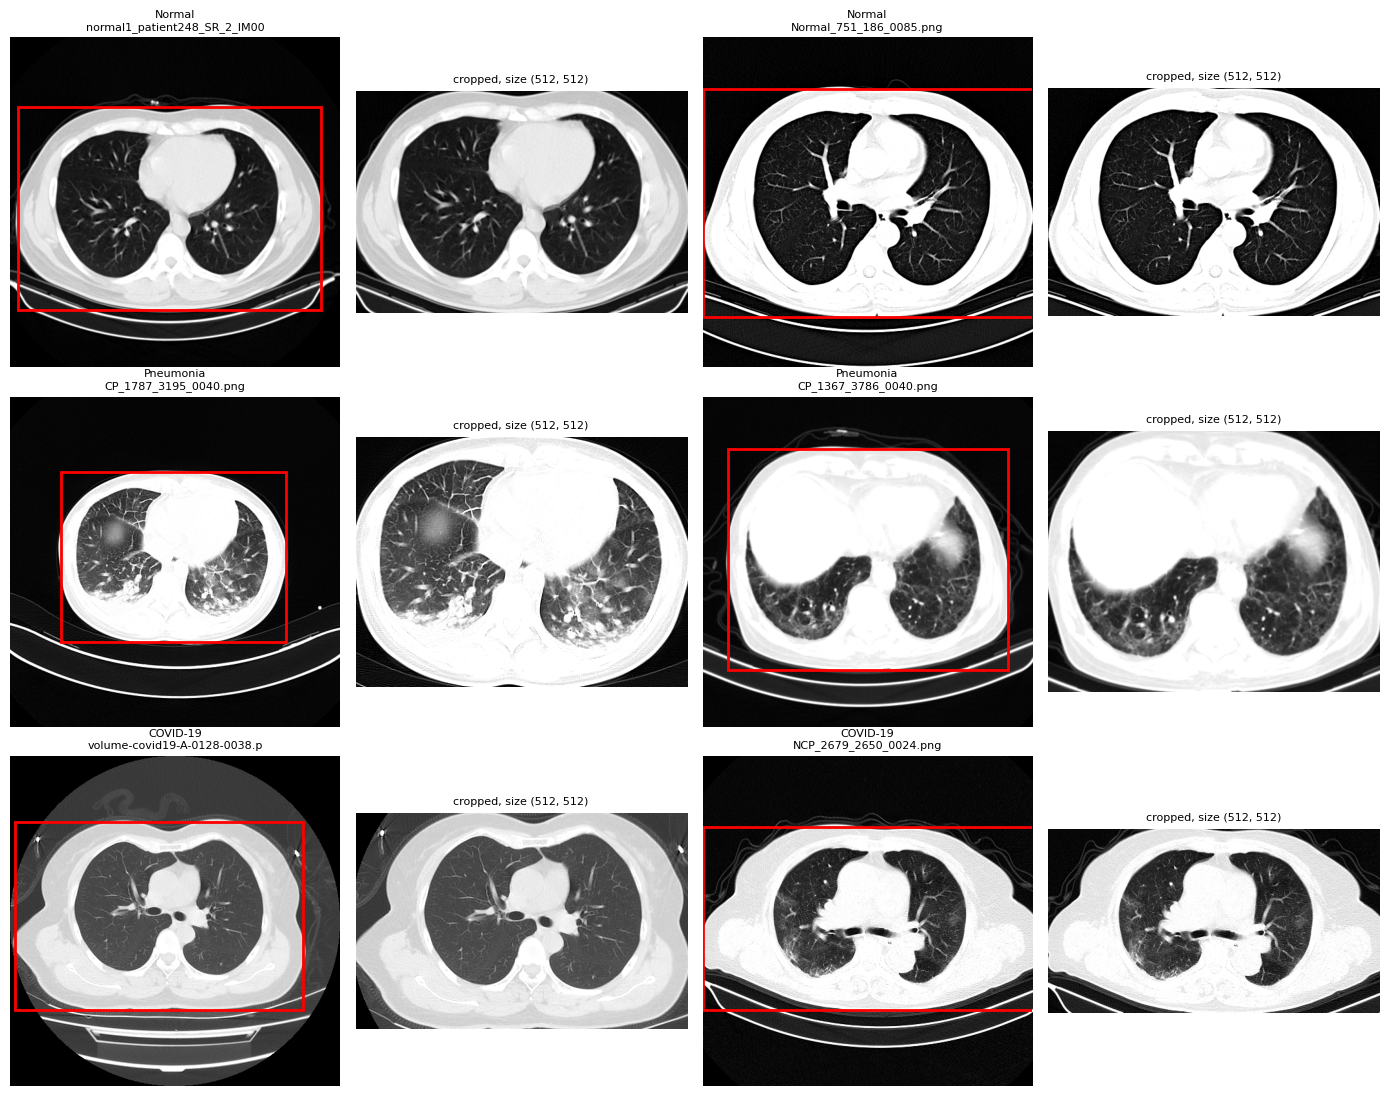

In [38]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

img_dir = f"{root}/3A_images"
class_names = ["Normal", "Pneumonia", "COVID-19"]

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for label in range(3):
    rows = sampled["train"][sampled["train"]["label"] == label].sample(2, random_state=1)
    for j, (_, r) in enumerate(rows.iterrows()):
        img = Image.open(f"{img_dir}/{r.filename}")

        # Left: full slice with the lung box drawn on it
        ax = axes[label, j * 2]
        ax.imshow(img, cmap="gray")
        ax.add_patch(patches.Rectangle((r.xmin, r.ymin), r.xmax - r.xmin, r.ymax - r.ymin,
                                       fill=False, edgecolor="red", linewidth=2))
        ax.set_title(f"{class_names[label]}\n{r.filename[:28]}", fontsize=8)
        ax.axis("off")

        # Right: the cropped lung region (what the model will actually get)
        ax = axes[label, j * 2 + 1]
        ax.imshow(img.crop((r.xmin, r.ymin, r.xmax, r.ymax)), cmap="gray")
        ax.set_title(f"cropped, size {img.size}", fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
# Map each person to their data source using the metadata
src = meta.set_index("patient id")["source"]
tr = sampled["train"].copy()
tr["source"] = tr["patient_id"].map(src).fillna("radiopaedia.org")

table = pd.crosstab(tr["source"], tr["label"].map(dict(enumerate(class_names))))
print(table)

label            COVID-19  Normal  Pneumonia
source                                      
CNCB                  833    2596       4373
COVID-19-CT-Seg        30       0          0
COVID-CT-MD            53       0        507
COVID-CTset            14    2175          0
LIDC-IDRI               0     330          0
STOIC                2395       0          0
Stony Brook           104       0          0
TCIA                  638       0          0
iCTCF                1189       0          0
radiopaedia.org        77     232        453


In [40]:
for name, df in sampled.items():
    df["source"] = df["patient_id"].map(src).fillna("radiopaedia.org")
    df.to_csv(f"/kaggle/working/splits/{name}.csv", index=False)
    print(name, "CNCB slices:", (df["source"] == "CNCB").sum(),
          "| classes in CNCB:", sorted(df.loc[df["source"] == "CNCB", "label"].unique()))

train CNCB slices: 7802 | classes in CNCB: [np.int64(0), np.int64(1), np.int64(2)]
val CNCB slices: 1019 | classes in CNCB: [np.int64(0), np.int64(1), np.int64(2)]
test CNCB slices: 1176 | classes in CNCB: [np.int64(0), np.int64(1), np.int64(2)]


In [41]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class CTDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(f"{self.img_dir}/{r.filename}").convert("L")
        img = img.crop((r.xmin, r.ymin, r.xmax, r.ymax))      # lungs only
        return self.transform(img), int(r.label)

datasets = {
    "train": CTDataset(sampled["train"], img_dir, train_tf),
    "val":   CTDataset(sampled["val"],   img_dir, eval_tf),
    "test":  CTDataset(sampled["test"],  img_dir, eval_tf),
}
loaders = {
    name: DataLoader(ds, batch_size=64, shuffle=(name == "train"),
                     num_workers=4, pin_memory=True)
    for name, ds in datasets.items()
}

x, y = next(iter(loaders["train"]))
print("batch images:", x.shape, "| labels:", y[:10].tolist())

batch images: torch.Size([64, 3, 224, 224]) | labels: [0, 1, 2, 1, 0, 2, 0, 2, 2, 0]


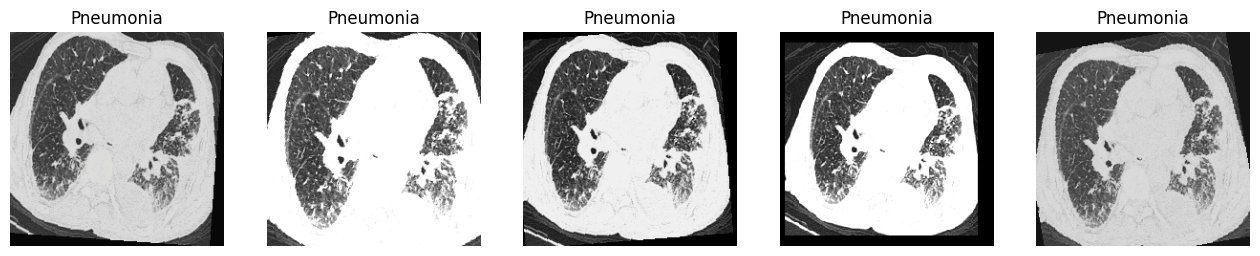

In [42]:
def show(t):   # undo the normalization so the image displays properly
    return (t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax in axes:
    img, label = datasets["train"][0]          # same slice, new random augmentation each time
    ax.imshow(show(img)); ax.set_title(class_names[label]); ax.axis("off")
plt.show()

In [43]:
import timm

device = torch.device("cuda")
model = timm.create_model("efficientnet_b0", pretrained=True,
                          num_classes=3, drop_rate=0.3).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params / 1e6:.1f}M parameters")

model.eval()
with torch.no_grad():
    logits = model(x[:4].to(device))
print("output shape:", logits.shape)
print("probabilities:\n", logits.softmax(dim=1).cpu().numpy().round(3))
print("true labels:", y[:4].tolist())

4.0M parameters
output shape: torch.Size([4, 3])
probabilities:
 [[1.    0.    0.   ]
 [0.236 0.    0.764]
 [1.    0.    0.   ]
 [0.998 0.002 0.   ]]
true labels: [0, 1, 2, 1]


In [44]:
import time
from sklearn.metrics import f1_score

EPOCHS = 10
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-4, total_steps=EPOCHS * len(loaders["train"]), pct_start=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, train):
    model.train(train)                      # train mode (dropout on) or eval mode
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()   # backpropagation
            scaler.step(optimizer)          # update the weights
            scaler.update()
            scheduler.step()                # adjust the learning rate
        total_loss += loss.item() * len(y)
        preds.append(logits.argmax(1).cpu())
        labels.append(y.cpu())
    preds, labels = torch.cat(preds), torch.cat(labels)
    acc = (preds == labels).float().mean().item()
    f1 = f1_score(labels, preds, average="macro")
    return total_loss / len(labels), acc, f1

best_f1, patience, bad_epochs, history = 0.0, 3, 0, []
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(loaders["train"], train=True)
    va_loss, va_acc, va_f1 = run_epoch(loaders["val"], train=False)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                        train_acc=tr_acc, val_acc=va_acc, val_f1=va_f1))
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f} | {time.time() - t0:.0f}s")

    if va_f1 > best_f1:
        best_f1, bad_epochs = va_f1, 0
        torch.save(model.state_dict(), "/kaggle/working/best.pt")
        print("   ↳ new best, saved")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("Early stopping: no improvement for", patience, "epochs")
            break

/tmp/ipykernel_51/549133646.py:24: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                # adjust the learning rate


Epoch  1 | train loss 1.194 acc 0.741 | val loss 1.246 acc 0.712 F1 0.710 | 57s
   ↳ new best, saved
Epoch  2 | train loss 0.205 acc 0.937 | val loss 1.341 acc 0.771 F1 0.760 | 57s
   ↳ new best, saved
Epoch  3 | train loss 0.095 acc 0.968 | val loss 1.619 acc 0.777 F1 0.758 | 57s
Epoch  4 | train loss 0.071 acc 0.978 | val loss 2.077 acc 0.755 F1 0.736 | 57s
Epoch  5 | train loss 0.048 acc 0.984 | val loss 1.845 acc 0.763 F1 0.739 | 57s
Early stopping: no improvement for 3 epochs


In [45]:
from sklearn.metrics import confusion_matrix, classification_report

model.load_state_dict(torch.load("/kaggle/working/best.pt"))
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in loaders["val"]:
        all_preds.append(model(x.to(device)).argmax(1).cpu())
        all_labels.append(y)
all_preds, all_labels = torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

print(confusion_matrix(all_labels, all_preds))
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

[[611  46   9]
 [ 48 590  28]
 [113 215 338]]
              precision    recall  f1-score   support

      Normal      0.791     0.917     0.850       666
   Pneumonia      0.693     0.886     0.778       666
    COVID-19      0.901     0.508     0.649       666

    accuracy                          0.770      1998
   macro avg      0.795     0.770     0.759      1998
weighted avg      0.795     0.770     0.759      1998



In [46]:
v = sampled["val"].copy()
v["pred"] = all_preds
v["correct"] = v["pred"] == v["label"]

# Accuracy per class and source
print(v.groupby(["label", "source"])["correct"].agg(["mean", "count"]).round(3))

# For COVID slices only: where did they go?
covid = v[v["label"] == 2]
print("\nCOVID slices, predicted as:")
print(pd.crosstab(covid["source"], covid["pred"].map(dict(enumerate(class_names)))))

                        mean  count
label source                       
0     CNCB             0.956    180
      COVID-CT-MD      0.724    127
      COVID-CTset      0.993    299
      LIDC-IDRI        0.833     60
1     CNCB             0.924    538
      COVID-CT-MD      0.727    128
2     CNCB             0.654    301
      COVID-CT-MD      0.200    150
      COVID-CTset      0.564    117
      TCIA             0.574     68
      radiopaedia.org  0.200     30

COVID slices, predicted as:
pred             COVID-19  Normal  Pneumonia
source                                      
CNCB                  197       1        103
COVID-CT-MD            30      60         60
COVID-CTset            66      36         15
TCIA                   39       2         27
radiopaedia.org         6      14         10


In [47]:
splits["train"]["source"] = splits["train"]["patient_id"].map(src).fillna("radiopaedia.org")

def sample_balanced(df, per_class, max_per_person=15, seed=42):
    rng = np.random.default_rng(seed)
    picked = []
    for label in [0, 1, 2]:
        sub = df[df["label"] == label]
        # how many slices each source can give (after the per-person cap)
        cap = {s: int(g.groupby("person_id").size().clip(upper=max_per_person).sum())
               for s, g in sub.groupby("source")}
        quota, remaining = {s: 0 for s in cap}, per_class
        while remaining > 0:                       # share the quota out evenly
            open_s = [s for s in cap if quota[s] < cap[s]]
            if not open_s:
                break
            share = max(1, remaining // len(open_s))
            for s in open_s:
                add = min(share, cap[s] - quota[s], remaining)
                quota[s] += add
                remaining -= add
                if remaining == 0:
                    break
        for s, q in quota.items():                 # then pick people within each source
            groups = dict(tuple(sub[sub["source"] == s].groupby("person_id")))
            people = np.array(list(groups), dtype=object)
            rng.shuffle(people)
            taken = 0
            for pid in people:
                if taken >= q:
                    break
                part = even_take(groups[pid], min(max_per_person, q - taken))
                picked.append(part)
                taken += len(part)
    return pd.concat(picked).sample(frac=1, random_state=seed).reset_index(drop=True)

train2 = sample_balanced(splits["train"], per_class=5333)
train2.to_csv("/kaggle/working/splits/train_balanced.csv", index=False)
print(len(train2), "slices,", train2["person_id"].nunique(), "people\n")
print(pd.crosstab(train2["source"], train2["label"].map(dict(enumerate(class_names)))))

15430 slices, 1187 people

label            COVID-19  Normal  Pneumonia
source                                      
CNCB                  656    2160       4351
COVID-19-CT-Seg        90       0          0
COVID-CT-MD           656       0        463
COVID-CTset           656    2139          0
LIDC-IDRI               0     330          0
STOIC                 655       0          0
Stony Brook           655       0          0
TCIA                  655       0          0
iCTCF                 655       0          0
radiopaedia.org       655     135        519


In [48]:
add_noise = T.Lambda(lambda t: (t + 0.03 * torch.randn_like(t)).clamp(0, 1))

train_tf2 = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomEqualize(p=1.0),                                   # normalize contrast per image
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.85, 1.15)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.RandomApply([add_noise], p=0.3),
    T.Normalize(MEAN, STD),
])
eval_tf2 = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomEqualize(p=1.0),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

datasets2 = {
    "train": CTDataset(train2, img_dir, train_tf2),
    "val":   CTDataset(sampled["val"], img_dir, eval_tf2),
    "test":  CTDataset(sampled["test"], img_dir, eval_tf2),
}
loaders2 = {
    name: DataLoader(ds, batch_size=64, shuffle=(name == "train"), num_workers=4, pin_memory=True)
    for name, ds in datasets2.items()
}

In [49]:
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=3, drop_rate=0.3).to(device)
loaders = loaders2                                             # run_epoch uses `loaders`
EPOCHS = 12
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-4, total_steps=EPOCHS * len(loaders["train"]), pct_start=0.1)
scaler = torch.amp.GradScaler("cuda")

best_f1, patience, bad_epochs = 0.0, 4, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, _ = run_epoch(loaders["train"], train=True)
    va_loss, va_acc, va_f1 = run_epoch(loaders["val"], train=False)
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f} | {time.time() - t0:.0f}s")
    if va_f1 > best_f1:
        best_f1, bad_epochs = va_f1, 0
        torch.save(model.state_dict(), "/kaggle/working/best_exp2.pt")
        print("   ↳ new best, saved")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("Early stopping"); break

/tmp/ipykernel_51/549133646.py:24: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                # adjust the learning rate


Epoch  1 | train loss 2.317 acc 0.556 | val loss 1.368 acc 0.675 F1 0.673 | 297s
   ↳ new best, saved
Epoch  2 | train loss 0.860 acc 0.765 | val loss 1.042 acc 0.719 F1 0.717 | 63s
   ↳ new best, saved
Epoch  3 | train loss 0.637 acc 0.840 | val loss 0.834 acc 0.758 F1 0.753 | 63s
   ↳ new best, saved
Epoch  4 | train loss 0.531 acc 0.888 | val loss 0.756 acc 0.766 F1 0.767 | 63s
   ↳ new best, saved
Epoch  5 | train loss 0.478 acc 0.915 | val loss 0.709 acc 0.791 F1 0.791 | 63s
   ↳ new best, saved
Epoch  6 | train loss 0.454 acc 0.930 | val loss 0.671 acc 0.802 F1 0.802 | 63s
   ↳ new best, saved
Epoch  7 | train loss 0.428 acc 0.944 | val loss 0.643 acc 0.828 F1 0.826 | 64s
   ↳ new best, saved
Epoch  8 | train loss 0.411 acc 0.953 | val loss 0.642 acc 0.828 F1 0.827 | 68s
   ↳ new best, saved
Epoch  9 | train loss 0.397 acc 0.961 | val loss 0.678 acc 0.817 F1 0.813 | 66s
Epoch 10 | train loss 0.392 acc 0.963 | val loss 0.643 acc 0.836 F1 0.835 | 66s
   ↳ new best, saved
Epoch 11 |

In [50]:
from sklearn.metrics import recall_score

def evaluate(weights, loader, df):
    m = timm.create_model("efficientnet_b0", pretrained=False, num_classes=3).to(device)
    m.load_state_dict(torch.load(weights)); m.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            preds.append(m(x.to(device)).argmax(1).cpu())
    p, y = torch.cat(preds).numpy(), df["label"].values
    cncb = (df["source"] == "CNCB").values
    return {"macro_F1": f1_score(y, p, average="macro"),
            "COVID_recall": recall_score(y, p, labels=[2], average="macro"),
            "CNCB_F1": f1_score(y[cncb], p[cncb], average="macro")}

val_loader_exp1 = DataLoader(CTDataset(sampled["val"], img_dir, eval_tf), batch_size=128, num_workers=4)
results = pd.DataFrame({
    "Exp 1 (baseline)": evaluate("/kaggle/working/best.pt", val_loader_exp1, sampled["val"]),
    "Exp 2 (balanced + aug + smoothing)": evaluate("/kaggle/working/best_exp2.pt", loaders2["val"], sampled["val"]),
}).round(3)
print(results)

              Exp 1 (baseline)  Exp 2 (balanced + aug + smoothing)
macro_F1                 0.759                               0.834
COVID_recall             0.508                               0.740
CNCB_F1                  0.850                               0.871


In [51]:
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, confusion_matrix

final = timm.create_model("efficientnet_b0", pretrained=False, num_classes=3).to(device)
final.load_state_dict(torch.load("/kaggle/working/best_exp2.pt"))
final.eval()

def get_logits(loader):
    out = []
    with torch.no_grad():
        for x, _ in loader:
            out.append(final(x.to(device)).float().cpu())
    return torch.cat(out).numpy()

val_logits, test_logits = get_logits(loaders2["val"]), get_logits(loaders2["test"])
y_val, y_test = sampled["val"]["label"].values, sampled["test"]["label"].values
test_df = sampled["test"].reset_index(drop=True)

# 1. Temperature scaling, fitted on VAL only
def nll(T):
    return F.cross_entropy(torch.tensor(val_logits / T), torch.tensor(y_val)).item()
T = minimize_scalar(nll, bounds=(0.05, 10), method="bounded").x
probs = torch.softmax(torch.tensor(test_logits / T), dim=1).numpy()
pred = probs.argmax(1)

def ece(prob, y, bins=10):
    conf, correct = prob.max(1), prob.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    return sum(((conf > lo) & (conf <= hi)).mean() * abs(correct[(conf > lo) & (conf <= hi)].mean() - conf[(conf > lo) & (conf <= hi)].mean())
               for lo, hi in zip(edges[:-1], edges[1:]) if ((conf > lo) & (conf <= hi)).any())
raw = torch.softmax(torch.tensor(test_logits), dim=1).numpy()
print(f"Temperature T = {T:.2f} | calibration error (ECE) before {ece(raw, y_test):.3f} -> after {ece(probs, y_test):.3f}\n")

# 2. Metrics
def metrics(y, p, prob):
    cm = confusion_matrix(y, p, labels=[0, 1, 2])
    out = {"accuracy": (y == p).mean(), "macro_F1": f1_score(y, p, average="macro"),
           "macro_AUC": roc_auc_score(y, prob, multi_class="ovr")}
    for k, name in enumerate(class_names):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
        out[f"{name} sensitivity"] = tp / (tp + fn)
        out[f"{name} specificity"] = tn / (tn + fp)
    return out

# 3. Confidence intervals by resampling PEOPLE, not slices
persons = test_df["person_id"].values
idx_by_person = {p: np.flatnonzero(persons == p) for p in np.unique(persons)}
people = np.array(list(idx_by_person), dtype=object)
rng, boot = np.random.default_rng(0), []
for _ in range(1000):
    idx = np.concatenate([idx_by_person[p] for p in rng.choice(people, len(people))])
    if len(np.unique(y_test[idx])) == 3:
        boot.append(metrics(y_test[idx], pred[idx], probs[idx]))
boot = pd.DataFrame(boot)

summary = pd.DataFrame({"value": metrics(y_test, pred, probs),
                        "95% CI low": boot.quantile(0.025),
                        "95% CI high": boot.quantile(0.975)}).round(3)
print(summary, "\n")
print("Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(y_test, pred), "\n")

# 4. CNCB-only and per-person results
cncb = (test_df["source"] == "CNCB").values
print("CNCB-only macro F1:", round(f1_score(y_test[cncb], pred[cncb], average="macro"), 3))

per_person = (test_df.assign(p0=probs[:, 0], p1=probs[:, 1], p2=probs[:, 2])
              .groupby("person_id").agg(label=("label", "first"), p0=("p0", "mean"),
                                        p1=("p1", "mean"), p2=("p2", "mean")))
person_pred = per_person[["p0", "p1", "p2"]].values.argmax(1)
print(f"Per-person accuracy: {(person_pred == per_person['label'].values).mean():.3f} "
      f"on {len(per_person)} people")

np.savez("/kaggle/working/test_outputs.npz", logits=test_logits, probs=probs, y=y_test, T=T)

Temperature T = 1.07 | calibration error (ECE) before 0.017 -> after 0.025

                       value  95% CI low  95% CI high
accuracy               0.852       0.794        0.905
macro_F1               0.853       0.790        0.905
macro_AUC              0.952       0.910        0.982
Normal sensitivity     0.844       0.725        0.945
Normal specificity     0.971       0.942        0.990
Pneumonia sensitivity  0.841       0.720        0.939
Pneumonia specificity  0.942       0.903        0.974
COVID-19 sensitivity   0.871       0.796        0.933
COVID-19 specificity   0.865       0.790        0.933 

Confusion matrix (rows = true, cols = predicted):
 [[562   7  97]
 [ 23 560  83]
 [ 16  70 580]] 

CNCB-only macro F1: 0.913
Per-person accuracy: 0.911 on 90 people


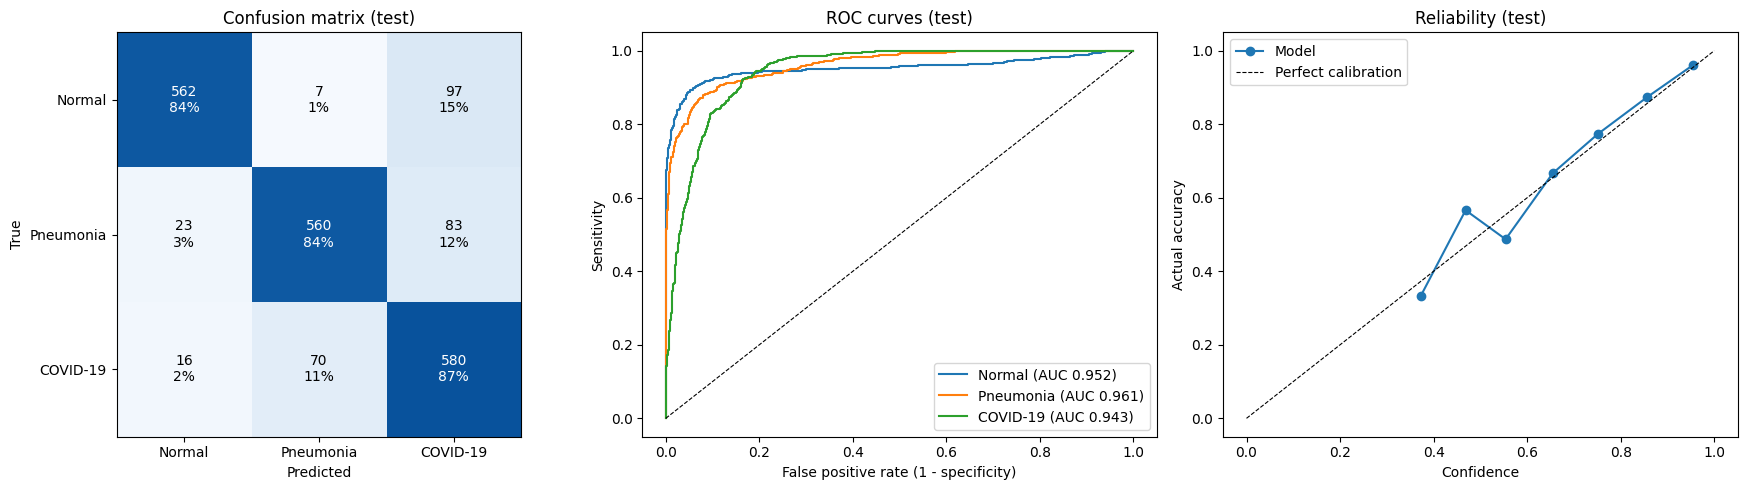

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

os.makedirs("/kaggle/working/reports", exist_ok=True)
raw_probs = torch.softmax(torch.tensor(test_logits), dim=1).numpy()   # no temperature scaling

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion matrix (counts + row percentages)
cm = confusion_matrix(y_test, pred)
norm = cm / cm.sum(1, keepdims=True)
ax = axes[0]
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center",
                color="white" if norm[i, j] > 0.6 else "black")
ax.set_xticks(range(3), class_names); ax.set_yticks(range(3), class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test)")

# 2. ROC curves, one class vs the rest
ax = axes[1]
for k, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test == k, raw_probs[:, k])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test == k, raw_probs[:, k]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("Sensitivity")
ax.set_title("ROC curves (test)"); ax.legend(loc="lower right")

# 3. Reliability diagram: does 80% confidence mean 80% correct?
ax = axes[2]
conf, correct = raw_probs.max(1), raw_probs.argmax(1) == y_test
edges = np.linspace(0, 1, 11)
centers, accs = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() > 0:
        centers.append(conf[m].mean()); accs.append(correct[m].mean())
ax.plot(centers, accs, "o-", label="Model")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfect calibration")
ax.set_xlabel("Confidence"); ax.set_ylabel("Actual accuracy"); ax.set_title("Reliability (test)"); ax.legend()

fig.tight_layout()
fig.savefig("/kaggle/working/reports/test_evaluation.png", dpi=150)
plt.show()

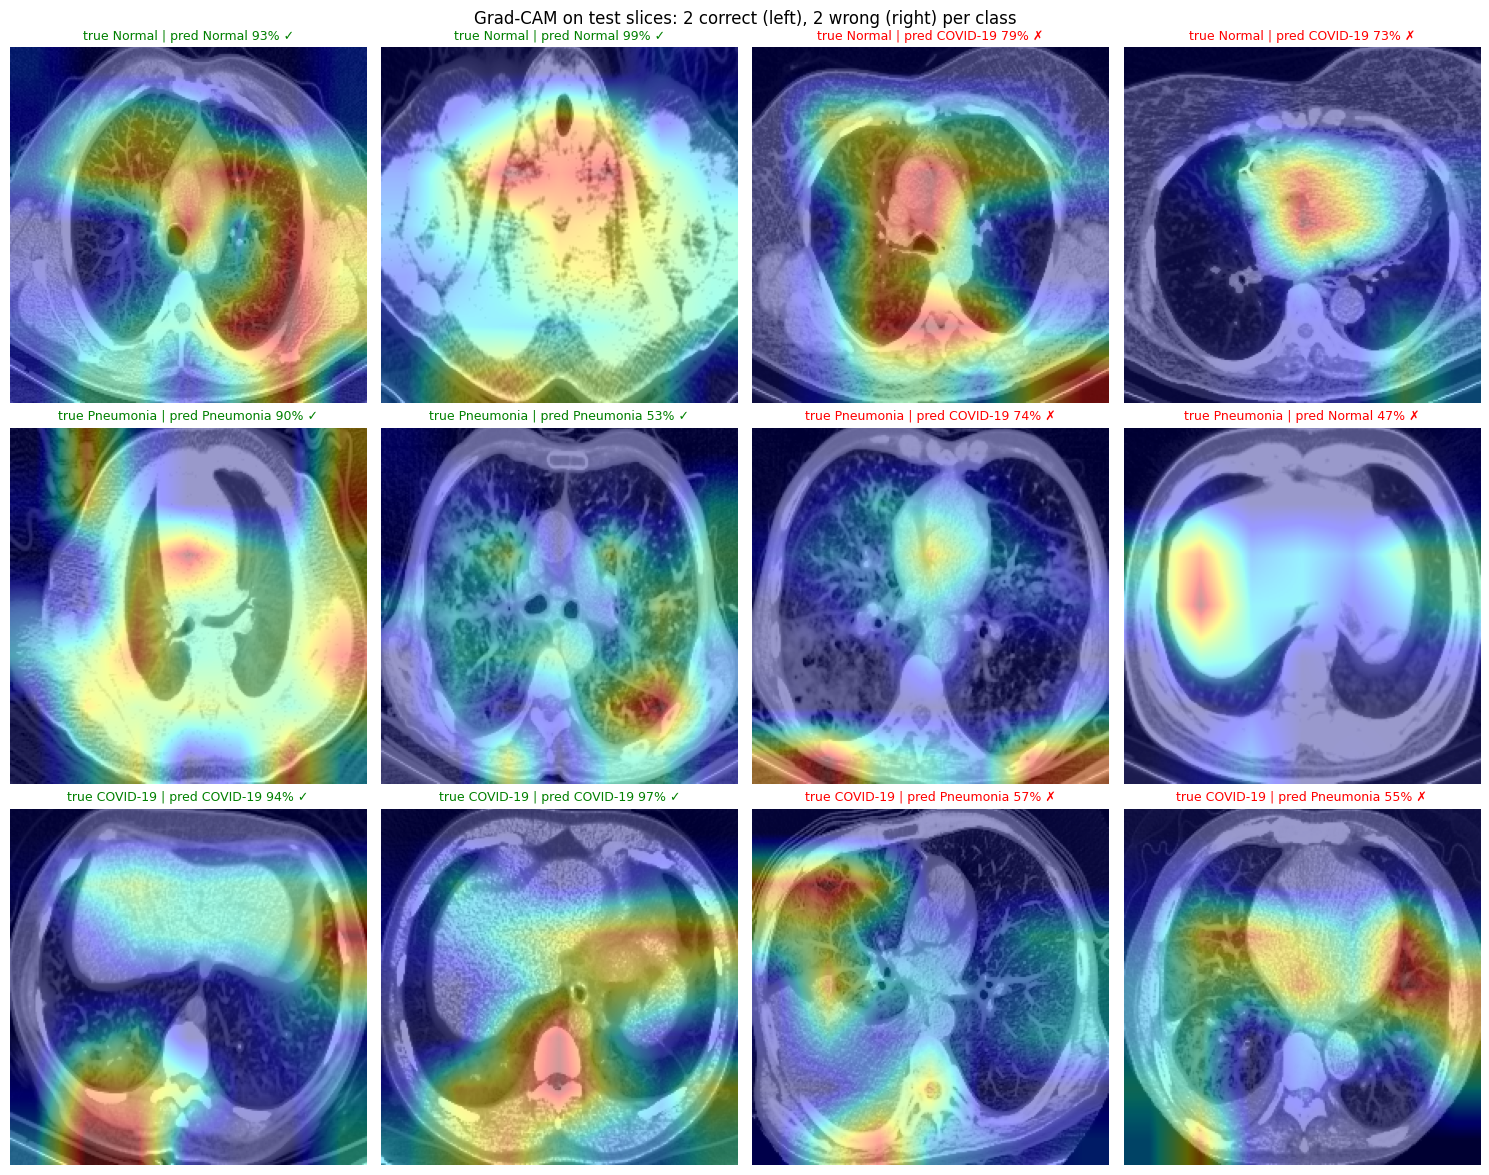

In [53]:
import torch.nn.functional as F

def grad_cam(model, x, target):
    with torch.enable_grad():
        feats = model.forward_features(x)          # last feature maps, shape (1, C, 7, 7)
        feats.retain_grad()
        logits = model.forward_head(feats)
        model.zero_grad()
        logits[0, target].backward()               # how does the target score depend on each feature?
        weights = feats.grad.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * feats).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

test_ds = loaders2["test"].dataset
rng = np.random.default_rng(1)
fig, axes = plt.subplots(3, 4, figsize=(15, 12))
for k in range(3):
    right = np.flatnonzero((y_test == k) & (pred == k))
    wrong = np.flatnonzero((y_test == k) & (pred != k))
    picks = list(rng.choice(right, 2, replace=False)) + list(rng.choice(wrong, 2, replace=False))
    for j, i in enumerate(picks):
        x, _ = test_ds[i]
        cam = grad_cam(final, x.unsqueeze(0).to(device), target=int(pred[i]))
        img = (x[0] * STD[0] + MEAN[0]).clamp(0, 1).numpy()      # undo normalization for display
        ax = axes[k, j]
        ax.imshow(img, cmap="gray")
        ax.imshow(cam, cmap="jet", alpha=0.4)
        ok = pred[i] == k
        ax.set_title(f"true {class_names[k]} | pred {class_names[pred[i]]} "
                     f"{raw_probs[i].max():.0%} {'✓' if ok else '✗'}",
                     fontsize=9, color="green" if ok else "red")
        ax.axis("off")
fig.suptitle("Grad-CAM on test slices: 2 correct (left), 2 wrong (right) per class")
fig.tight_layout()
fig.savefig("/kaggle/working/reports/gradcam.png", dpi=130)
plt.show()